In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit


In [5]:
data = sm.datasets.sunspots.load_pandas().data
sunspots = data["SUNACTIVITY"].values

# Create lagged features
def add_lagged_features(data, lag=12):
    X, y = [], []

    for i in range(lag, len(data)):
        X.append(data[i-lag:i])
        y.append(data[i])

    return np.array(X), np.array(y)

X, y = add_lagged_features(sunspots, lag=12)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

# Scale inputs
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Scale targets
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

In [6]:
neuron_counts = range(10, 301, 10)

results = []
predictions = {}

for neurons in neuron_counts:

    mlp = MLPRegressor(
        hidden_layer_sizes=(neurons, neurons),
        activation="relu",
        solver="adam",
        max_iter=2500,
        random_state=42
    )

    # Train model
    mlp.fit(X_train_scaled, y_train_scaled)

    # Make predictions
    y_pred_scaled = mlp.predict(X_test_scaled)

    # Convert predictions to original scale
    y_pred = y_scaler.inverse_transform(
        y_pred_scaled.reshape(-1, 1)
    ).ravel()

    # Evaluate
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        "Neurons": neurons,
        "RMSE": rmse,
        "MAE": mae
    })

    predictions[neurons] = y_pred

results_df = pd.DataFrame(results)

print(results_df)

    Neurons       RMSE        MAE
0        10  20.530598  15.171772
1        20  22.223905  15.520555
2        30  18.917304  14.054313
3        40  19.979245  14.704402
4        50  20.886130  16.122600
5        60  19.728455  15.814695
6        70  22.542517  17.130149
7        80  18.703942  14.178618
8        90  22.610131  16.730053
9       100  22.505863  16.744912
10      110  20.595705  16.014133
11      120  20.905975  16.361476
12      130  23.688051  17.565302
13      140  23.280853  18.037315
14      150  22.725143  17.481936
15      160  23.006650  17.086739
16      170  21.116470  15.842620
17      180  21.108305  16.494603
18      190  21.483502  17.002720
19      200  21.227201  16.201561
20      210  22.578296  16.929858
21      220  21.426291  16.638909
22      230  24.224276  18.072086
23      240  21.487273  16.396432
24      250  21.474402  16.568853
25      260  22.029535  16.350962
26      270  22.087972  17.350194
27      280  20.641940  16.034031
28      290  2

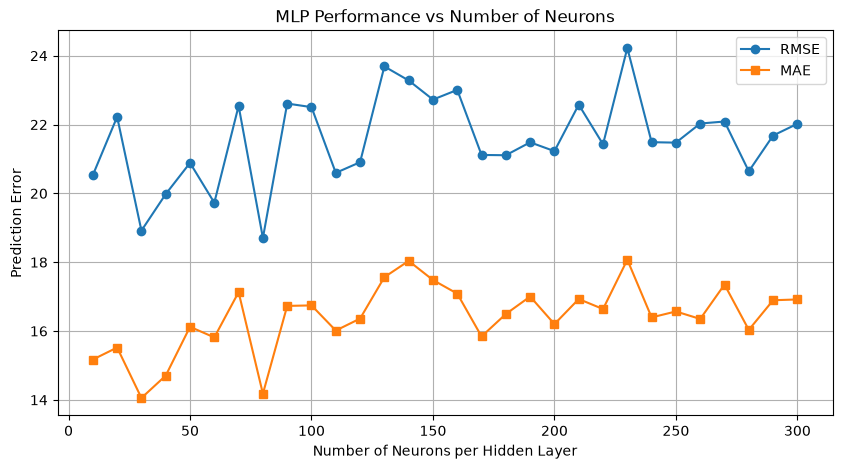

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Neurons"],
    results_df["RMSE"],
    marker="o",
    label="RMSE"
)

plt.plot(
    results_df["Neurons"],
    results_df["MAE"],
    marker="s",
    label="MAE"
)

plt.xlabel("Number of Neurons per Hidden Layer")
plt.ylabel("Prediction Error")
plt.title("MLP Performance vs Number of Neurons")

plt.legend()
plt.grid(True)
plt.show()

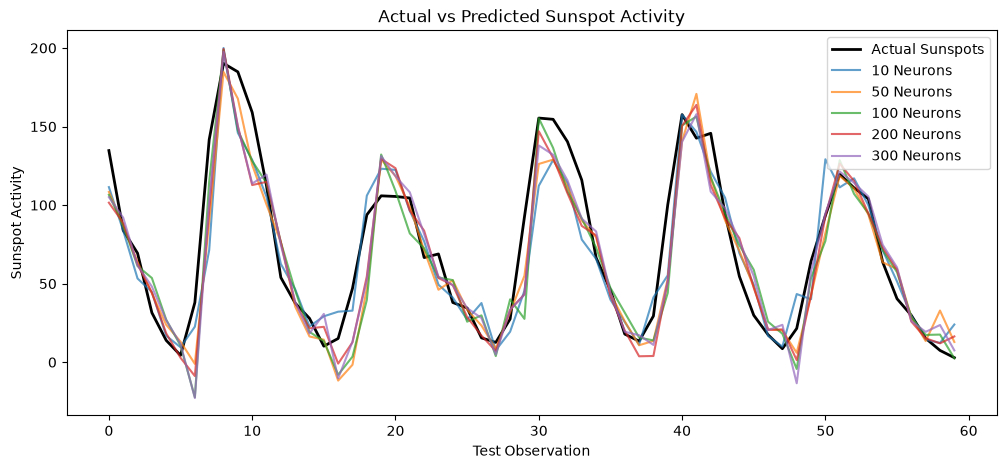

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test,
    label="Actual Sunspots",
    color="black",
    linewidth=2
)

for neurons in [10, 50, 100, 200, 300]:
    plt.plot(
        predictions[neurons],
        label=f"{neurons} Neurons",
        alpha=0.7
    )

plt.xlabel("Test Observation")
plt.ylabel("Sunspot Activity")
plt.title("Actual vs Predicted Sunspot Activity")

plt.legend()
plt.show()